# 02 — Embeddings & Vector Similarity from Scratch

## What you'll learn

An embedding is just a list of numbers — coordinates for meaning in a high-dimensional
space. Sentences about similar things end up near each other; sentences about different
things end up far apart. This notebook demystifies that by embedding 30 sentences across 3
obvious topics, computing similarity with raw numpy (no vector DB in sight), and then
literally looking at the result as a 2D scatter plot.


## Architecture

![Architecture diagram](https://mermaid.ink/img/Zmxvd2NoYXJ0IExSCiAgICBTWzMwIHNlbnRlbmNlczxici8-Y29va2luZyAvIGZvb3RiYWxsIC8gcHJvZ3JhbW1pbmddIC0tPiBFTUJbdGV4dC1lbWJlZGRpbmctMy1zbWFsbF0KICAgIEVNQiAtLT4gVlszMCB4IDE1MzYgdmVjdG9yc10KICAgIFYgLS0-IENPU1tSYXcgbnVtcHk6PGJyLz5jb3NpbmUgLyBkb3QgLyBldWNsaWRlYW5dCiAgICBWIC0tPiBVTUFQW1VNQVAgLT4gMkRdCiAgICBVTUFQIC0tPiBQTkdbc2VudGVuY2VfZW1iZWRkaW5nc18yZC5wbmdd?theme=dark)


## Setup

Runs fully local via [Ollama](https://ollama.com) — no API key needed. Start the Ollama server and pull the model first:

```bash
ollama pull bge-m3
```


In [1]:
from pathlib import Path

DATA_PATH = Path("data") / "sentences.json"

## `load_sentences` — shared helper: flatten the 3-topic sentence set

Flattens `data/sentences.json` (10 sentences each for cooking / football / programming)
into two parallel lists: the sentences themselves, and their topic labels.


In [2]:
import json


def load_sentences() -> tuple[list[str], list[str]]:
    """Returns (sentences, topics) as two parallel lists of equal length."""
    raw = json.loads(DATA_PATH.read_text())
    sentences, topics = [], []
    # flatten the {topic: [sentences]} dict into parallel lists so index i always
    # maps sentences[i] to the topic it came from
    for topic, sents in raw.items():
        for s in sents:
            sentences.append(s)
            topics.append(topic)
    return sentences, topics


sentences, topics = load_sentences()
print(f"Loaded {len(sentences)} sentences across {len(set(topics))} topics")
print(list(set(topics)))

Loaded 30 sentences across 3 topics
['programming', 'cooking', 'football']


## `raw_similarity` — embeddings are just coordinates for meaning

Embed the 30 sentences and compute pairwise similarity by hand with numpy, so nothing is
hidden behind a vector-DB abstraction. Then show cosine, dot product, and Euclidean
distance side by side on the same vectors — they usually agree on rank but not on scale,
which is a common source of confusion.


In [5]:
import numpy as np
from langchain_ollama import OllamaEmbeddings


def embed_sentences(sentences: list[str]) -> np.ndarray:
    embedder = OllamaEmbeddings(model="bge-m3")
    vectors = embedder.embed_documents(sentences)
    return np.array(vectors)


def cosine_similarity_matrix(vectors: np.ndarray) -> np.ndarray:
    # normalize every row to unit length first, so a plain dot product IS the cosine similarity
    norms = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    return norms @ norms.T


def dot_product_matrix(vectors: np.ndarray) -> np.ndarray:
    # unnormalized dot product - unlike cosine, this is sensitive to vector magnitude
    return vectors @ vectors.T


def euclidean_distance_matrix(vectors: np.ndarray) -> np.ndarray:
    # ||a - b||^2 = ||a||^2 + ||b||^2 - 2 a.b, expanded to avoid an O(n^2) python loop
    sq_norms = np.sum(vectors**2, axis=1)
    sq_dists = sq_norms[:, None] + sq_norms[None, :] - 2 * (vectors @ vectors.T)
    return np.sqrt(np.maximum(sq_dists, 0))

In [6]:
import numpy as np

print(f"Embedding {len(sentences)} sentences with bge-m3...")
vectors = embed_sentences(sentences)
print(f"Vector shape: {vectors.shape}  (1024 dimensions per sentence)\n")

cosine = cosine_similarity_matrix(vectors)
dot = dot_product_matrix(vectors)
euclid = euclidean_distance_matrix(vectors)

# Pick one sentence from each topic and show its nearest neighbors by cosine sim
anchors = [0, 10, 20]  # first sentence of cooking, football, programming
for i in anchors:
    print(f'Nearest neighbors of: "{sentences[i]}"  [{topics[i]}]')
    # sort all sentence indices by similarity to i, descending
    ranked = sorted(range(len(sentences)), key=lambda j: -cosine[i, j])
    for j in ranked[1:4]:  # skip itself
        print(
            f"  cos={cosine[i, j]:.3f}  dot={dot[i, j]:.1f}  "
            f"euclid={euclid[i, j]:.3f}  [{topics[j]}] {sentences[j]}"
        )
    print()

# Compare average similarity within a topic vs across topics - the gap is the
# signal that embeddings actually cluster by meaning, not just by wording
same_topic = [cosine[i, j] for i in range(30) for j in range(30) if i != j and topics[i] == topics[j]]
diff_topic = [cosine[i, j] for i in range(30) for j in range(30) if i != j and topics[i] != topics[j]]
print(f"Avg cosine similarity within same topic:      {np.mean(same_topic):.3f}")
print(f"Avg cosine similarity across different topics: {np.mean(diff_topic):.3f}")

Embedding 30 sentences with bge-m3...
Vector shape: (30, 1024)  (1024 dimensions per sentence)

Nearest neighbors of: "Simmer the tomato sauce for twenty minutes until it thickens."  [cooking]
  cos=0.637  dot=0.6  euclid=0.852  [cooking] Blend the soup until smooth, then adjust the seasoning.
  cos=0.614  dot=0.6  euclid=0.879  [cooking] Sear the steak on high heat for two minutes per side.
  cos=0.606  dot=0.6  euclid=0.887  [cooking] Marinate the tofu in soy sauce and ginger overnight.

Nearest neighbors of: "The striker curled the ball into the top corner from twenty yards."  [football]
  cos=0.705  dot=0.7  euclid=0.768  [football] The captain scored a header from a corner kick.
  cos=0.684  dot=0.7  euclid=0.795  [football] The goalkeeper punched the corner kick clear of the box.
  cos=0.626  dot=0.6  euclid=0.865  [football] The defender slid in with a perfectly timed tackle.

Nearest neighbors of: "The function throws an exception when the input list is empty."  [programming]
 

## `visualize` — literally look at the embeddings

Embeddings live in 1024 dimensions, which is impossible to look at directly. UMAP projects
them down to 2D while preserving local neighborhood structure, so topic clusters become
visible as literal clusters on a scatter plot.


In [8]:
import umap

OUTPUT_PATH = "sentence_embeddings_2d.png"


def project_to_2d(vectors):
    # n_neighbors must be < number of points; we only have 30 sentences
    reducer = umap.UMAP(n_neighbors=8, min_dist=0.3, random_state=42)
    return reducer.fit_transform(vectors)

/Users/pkaranje/workspace/pkaranje/yashjainio-youtube/rag-youtube/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Matplotlib is building the font cache; this may take a moment.
/Users/pkaranje/workspace/pkaranje/yashjainio-youtube/rag-youtube/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


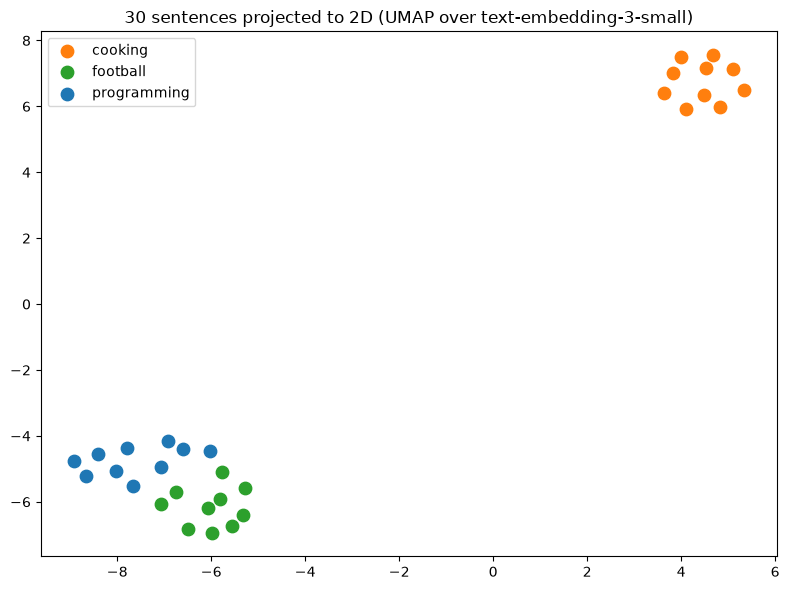

Saved plot to sentence_embeddings_2d.png
Expect 3 visually separated clusters — one per topic — with zero
topic labels ever passed into the embedding model.


In [10]:
import matplotlib.pyplot as plt

coords_2d = project_to_2d(vectors)

colors = {"cooking": "tab:orange", "football": "tab:green", "programming": "tab:blue"}
fig, ax = plt.subplots(figsize=(8, 6))
for topic, color in colors.items():
    # boolean mask selects just this topic's rows out of the full 2D projection
    mask = [t == topic for t in topics]
    ax.scatter(coords_2d[mask, 0], coords_2d[mask, 1], label=topic, color=color, s=80)

ax.set_title("30 sentences projected to 2D (UMAP over bge-m3)")
ax.legend()
fig.tight_layout()
# fig.savefig(OUTPUT_PATH, dpi=150)
plt.show()
print(f"Saved plot to {OUTPUT_PATH}")
print("Expect 3 visually separated clusters — one per topic — with zero")
print("topic labels ever passed into the embedding model.")

## Run it end-to-end

Running every cell above top to bottom already is the end-to-end flow for this episode:
raw-numpy similarity, then the 2D visualization. The cell below just re-confirms both
pieces produced output.


In [11]:
print("Raw similarity matrices computed:", cosine.shape, dot.shape, euclid.shape)
print("2D projection saved to:", OUTPUT_PATH)

Raw similarity matrices computed: (30, 30) (30, 30) (30, 30)
2D projection saved to: sentence_embeddings_2d.png


## Key concepts

1. **What an embedding is** — a fixed-length vector where geometric closeness approximates
   semantic closeness. `bge-m3` produces 1024-dimensional vectors.
2. **Cosine similarity vs. dot product vs. Euclidean distance** — cosine ignores vector
   magnitude (usually what you want for text); dot product doesn't; Euclidean measures
   straight-line distance. They usually agree on _ranking_ but differ in _scale_.
3. **Embedding model choice** — dimensions, speed/memory footprint, and benchmarks (MTEB
   leaderboard) all factor into picking a model; bigger isn't always better for RAG.
4. **Visualizing embeddings in 2D** — UMAP compresses 1024 dimensions down to 2 while
   preserving neighborhood structure, so topic clusters become visible without any topic
   label ever being given to the embedding model.
5. **Vector-store abstractions wrap this exact math** — LangChain's `VectorStore`
   interface (Chroma, Qdrant, FAISS, ...) hides the same cosine/dot-product math behind
   `.add_texts()` / `.similarity_search()`. See Episode 07 for choosing one and Episode 08
   for day-2 operations — no code for it here, this notebook stays at the raw-math layer.


## Try this yourself

1. Add 5 new sentences about a 4th topic (e.g. "weather") to `data/sentences.json` and
   rerun the visualization cells — confirm a 4th cluster appears.
2. Compare `cosine_similarity_matrix` vs `dot_product_matrix` rankings for the same anchor
   sentence — are the top-3 neighbors ever different?
3. Swap `bge-m3` for another local embedding model (e.g. `nomic-embed-text`) in `embed_sentences` and see
   whether the same-topic vs. different-topic similarity gap gets wider or narrower.


## Common pitfalls

- **Comparing dot products across models with different vector norms** — dot product is
  not scale-invariant; always check whether your embedding model normalizes its output.
- **Trusting 2D projections literally** — UMAP/t-SNE distort global distances to preserve
  local structure; two clusters being far apart in the plot doesn't mean much quantitatively.
- **Re-embedding the same text repeatedly** — embeddings are deterministic per model
  version; cache them instead of paying for the same API call twice (real vector DBs do
  this for you, which is the whole point of Episode 07).
